# 《到期日》滑块版：改参数，重跑实验

拖动滑块改实验假设，点“运行”，游戏会把四组重新跑一遍，结果和基准（默认设定，100 局）放在一起比较。规则版，没有 LLM；结果用来看假设的影响，不代表北京的真实情况。

**怎么用**

1. 在 Colab 或 Jupyter 里打开，从上到下运行全部（Run All）。游戏和数据都在这个文件里，不用下载别的。
2. 到下面“改参数”那一格拖滑块，点“运行”。默认每组 20 局，一般要等一到几分钟。
3. 结果显示在滑块下方，每次运行都会记进“运行记录”。

**局数少，结果就更不稳定。** 20 局时，交互影响的区间大约是 ±0.6，100 局时是 ±0.27。就算不动滑块，20 局的结果也会和基准略有不同，比如交互影响是 +1.02 ±0.55，基准是 +1.32 ±0.27。差别落在误差范围内就不要下结论；要写进报告的结论，把局数调到 100 再跑一次。

In [1]:
#@title 准备：载入工具和中文字体
import base64, gzip, json, os, subprocess, sys, tempfile, time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, clear_output, display
from matplotlib import font_manager

try:
    import ipywidgets as w
except ImportError:
    w = None

CJK = ["PingFang SC", "Hiragino Sans GB", "Heiti TC", "STHeiti", "Arial Unicode MS", "Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "Noto Sans CJK JP", "WenQuanYi Micro Hei"]
installed = {f.name for f in font_manager.fontManager.ttflist}
if "google.colab" in sys.modules and not installed & set(CJK):
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], capture_output=True)
    path = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
    if os.path.exists(path):
        font_manager.fontManager.addfont(path)
        installed = {f.name for f in font_manager.fontManager.ttflist}
found = [f for f in CJK if f in installed]
if not found:
    print("没有找到中文字体，图里的中文会显示成方块。安装任意一种中文字体后重新运行。")
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": found + ["DejaVu Sans"], "axes.unicode_minus": False, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#9a9ea4", "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
                     "xtick.color": "#6b6f76", "ytick.color": "#6b6f76", "figure.dpi": 110, "savefig.dpi": 110})
ORANGE, GREY, INK = "#d95926", "#6b6f76", "#1b1f24"

In [2]:
#@title 游戏代码和基准结果（已放在文件里，不用下载）
PACKED = """
...
"""
content = json.loads(gzip.decompress(base64.b64decode(PACKED)))
GAME_DIR = tempfile.mkdtemp(prefix="lease_day_")
for name, text in content["files"].items():
    target = os.path.join(GAME_DIR, name)
    os.makedirs(os.path.dirname(target), exist_ok=True)
    with open(target, "w", encoding="utf-8") as handle:
        handle.write(text)
sys.path.insert(0, os.path.join(GAME_DIR, "prototype"))
import slider_v06 as slider

BASE = content["baseline"]
# 想看规则代码：print(content["files"]["prototype/lease_day_v06.py"])

In [3]:
#@title 运行和画图
ARMS = {"A": dict(color=GREY, ls="-", label="A 没有新线，租金变化"), "A0": dict(color=GREY, ls="--", label="A0 没有新线，租金冻结"),
        "C": dict(color=ORANGE, ls="-", label="C 新线，租金变化"), "B": dict(color=ORANGE, ls="--", label="B 新线，租金冻结")}
OPENS, MONTHS, TAIL = slider.g.LINE_OPENS + 1, slider.g.MONTHS, slider.v.TAIL
SLIDERS = [("saving_scale", "快线省时（倍）", 0, 3, 0.25, "基准是果园 12 分钟、武夷花园 15 分钟"),
           ("demand_k", "询盘强度", 0, 0.6, 0.05, "房东对询盘变化的反应，0 表示只看空置率"),
           ("low_cost", "低价房数量（倍）", 0.2, 1.5, 0.1, "低价房和便宜单间，房间总数不变"),
           ("savings", "存款（倍）", 0.25, 2, 0.25, "基准是家庭收入的 1 到 3 倍"),
           ("rent_trend", "租金年增速", 0, 0.15, 0.01, "基准 0；2015 到 2018 年约 0.13"),
           ("wage_trend", "工资年增速", 0, 0.12, 0.01, "基准 0；2015 到 2018 年约 0.088"),
           ("stayer_share", "续租涨幅比例", 0, 1, 0.1, "续租者的涨幅占市场涨幅的比例")]
NAMES = {key: label for key, label, *_ in SLIDERS}
HISTORY = []

def settings_text(settings):
    changed = [f"{NAMES[k]} {settings[k]:g}" for k in NAMES if abs(settings[k] - slider.DEFAULTS[k]) > 1e-9]
    return "；".join(changed) if changed else "基准设定"

def number(row, signed):
    d = row["digits"]
    text = f"{row['value']:+,.{d}f}" if signed else f"{row['value']:,.{d}f}"
    return f"{text} ±{row['half']:,.{max(d, 1) if row['half'] >= 0.1 else 2}f}"

def show_tables(result):
    # 基准和本次是各自独立的估计，两个区间合起来判断差别是否超过误差
    base = {row["key"]: row for row in BASE["table"]}
    signed = lambda row: not row["key"].endswith("|C")
    rows = [dict(row, gap=abs(row["value"] - base[row["key"]]["value"]) > (row["half"] ** 2 + base[row["key"]]["half"] ** 2) ** 0.5) for row in result["table"]]
    def table(items):
        return pd.DataFrame({"指标": [r["label"] for r in items], "基准（100 局）": [number(base[r["key"]], signed(r)) for r in items], f"本次（{result['seeds']} 局）": [number(r, signed(r)) for r in items]}).set_index("指标")
    different = [r for r in rows if r["gap"]]
    same = [r for r in rows if not r["gap"]]
    if different:
        display(HTML("<b>和基准明显不同</b>"), table(different))
    display(HTML("<b>差别在误差范围内</b>"), table(same))

def show_charts(result, compare=True):
    panels = [("watch_commute", "受益区租客通勤（分钟）"), ("watch_rent", "受益区租金指数（起点 = 100）"), ("gap", "受益区租金差 C - A（指数点）"),
              ("inq_in", "受益区每间房每月询盘"), ("mode_in_subway", "受益区坐地铁的占比（%）"), ("cum_in", "开通后累计搬入受益区（人）")]
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
    for ax, (metric, title) in zip(axes.flat, panels):
        ax.axvline(OPENS - 0.5, color="#9a9ea4", lw=1)
        ax.axvspan(MONTHS - TAIL, MONTHS, color="#eceef0", lw=0, zorder=0)
        ax.set_xlim(0, MONTHS)
        ax.set_xticks([12, 24, 36, 48, 60])
        ax.grid(axis="y", color="#eceef0", lw=1)
        ax.set_axisbelow(True)
        ax.set_title(title)
        months = list(range(MONTHS + 1))
        if metric == "gap":
            m, h = result["gap"]["m"], result["gap"]["h"]
            xs = months[OPENS:]
            lo = [a - b for a, b in zip(m[OPENS:], h[OPENS:])]
            hi = [a + b for a, b in zip(m[OPENS:], h[OPENS:])]
            ax.fill_between(xs, lo, hi, color=ORANGE, alpha=0.14, lw=0)
            ax.plot(xs, m[OPENS:], color=ORANGE, lw=2)
            ax.axhline(0, color="#9a9ea4", lw=1)
            if compare:
                ax.plot(xs, BASE["gap"]["m"][OPENS:], color=INK, lw=1, ls=":")
            continue
        arms = ["A", "C"] if metric == "inq_in" else ["A0", "B", "A", "C"]
        start = 1 if metric == "inq_in" else 0
        for arm in arms:
            m, h = result["monthly"][metric][arm]["m"], result["monthly"][metric][arm]["h"]
            style = ARMS[arm]
            if arm in ("A", "C"):
                ax.fill_between(months[start:], [a - b for a, b in zip(m[start:], h[start:])], [a + b for a, b in zip(m[start:], h[start:])], color=style["color"], alpha=0.1, lw=0)
            ax.plot(months[start:], m[start:], color=style["color"], ls=style["ls"], lw=2 if style["ls"] == "-" else 1.6)
        if compare:
            ax.plot(months[start:], BASE["monthly"][metric]["C"]["m"][start:], color=INK, lw=1, ls=":")
        if metric == "inq_in" and max(result["monthly"][metric]["C"]["m"]) == 0:
            ax.text(0.5, 0.5, "询盘强度为 0 时不统计询盘", transform=ax.transAxes, ha="center", color=GREY)
    handles = [plt.Line2D([], [], color=ARMS[a]["color"], ls=ARMS[a]["ls"], lw=2, label=ARMS[a]["label"]) for a in ARMS]
    if compare:
        handles.append(plt.Line2D([], [], color=INK, ls=":", lw=1, label="基准的 C 组"))
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False, fontsize=10, bbox_to_anchor=(0.5, 1.03))
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    display(fig)
    plt.close(fig)

def show_history():
    display(HTML("<b>运行记录</b>"), pd.DataFrame(HISTORY).set_index("设定"))

def compute(seeds=20, workers=None, progress=None, **changes):
    unknown = set(changes) - set(slider.DEFAULTS)
    if unknown:
        raise ValueError(f"没有这些参数：{sorted(unknown)}。可以改的是：{sorted(slider.DEFAULTS)}")
    settings = {**slider.DEFAULTS, **changes}
    started = time.time()
    result = slider.summarize(slider.run(settings, seeds, workers=workers, progress=progress))
    rows = {row["key"]: row for row in result["table"]}
    pick = lambda key, d: f"{rows[key]['value']:+.{d}f} ±{rows[key]['half']:.{d}f}"
    HISTORY.append({"设定": settings_text(settings), "局数": seeds, "受益区通勤，直接效应": pick("watch_commute|direct", 1), "租金交互影响": pick("watch_rent|interaction", 2), "第 60 月租金差": pick("watch_rent|total", 2),
                    "低收入超 30%（%）": f"{rows['low_over30|C']['value']:.0f}", "累计离开": f"{rows['cum_left|C']['value']:.1f}", "累计被挡": f"{rows['cum_blocked|C']['value']:.0f}", "用时（秒）": round(time.time() - started)})
    return settings, result

def show_result(settings, result):
    display(HTML(f"<b>本次设定：</b>{settings_text(settings)}，每组 {result['seeds']} 局"))
    show_tables(result)
    show_charts(result)
    show_history()

def run_and_show(seeds=20, workers=None, progress=None, **changes):
    settings, result = compute(seeds, workers, progress, **changes)
    show_result(settings, result)

def show_controls():
    if w is None:
        print("这个环境没有 ipywidgets，滑块显示不出来。可以运行 pip install ipywidgets，或者像下一格那样直接写参数。")
        return None
    label = {"description_width": "120px"}
    sliders, rows = {}, []
    for key, name, low, high, step, note in SLIDERS:
        sliders[key] = w.FloatSlider(value=slider.DEFAULTS[key], min=low, max=high, step=step, description=name, readout_format=".2f", continuous_update=False, style=label, layout=w.Layout(width="440px"))
        rows.append(w.HBox([sliders[key], w.HTML(f"<span style='color:{GREY};font-size:12px'>{note}</span>")]))
    seeds = w.IntSlider(value=20, min=5, max=100, step=5, description="每组局数", continuous_update=False, style=label, layout=w.Layout(width="440px"))
    rows.append(w.HBox([seeds, w.HTML(f"<span style='color:{GREY};font-size:12px'>局数越多越稳定，也越慢</span>")]))
    go = w.Button(description="运行", button_style="primary")
    reset = w.Button(description="恢复默认")
    bar = w.IntProgress(value=0, min=0, max=1, layout=w.Layout(width="240px"))
    status = w.HTML()
    out = w.Output()

    def tick(done, total):
        bar.max, bar.value = total, done
        status.value = f"<span style='color:{GREY}'>已跑 {done} / {total} 局</span>"

    def on_run(_):
        go.disabled = True
        started = time.time()
        try:
            settings, result = compute(seeds.value, progress=tick, **{k: s.value for k, s in sliders.items()})
            status.value = f"<span style='color:{GREY}'>完成，用时 {time.time() - started:.0f} 秒</span>"
            with out:
                clear_output(wait=True)
                show_result(settings, result)
        except Exception as error:
            status.value = "<span style='color:#c03030'>这组设定没有跑完</span>"
            with out:
                clear_output(wait=True)
                print("这组设定没有跑完，可以把参数调得温和一些再试：", repr(error))
        finally:
            go.disabled = False

    def on_reset(_):
        for key, s in sliders.items():
            s.value = slider.DEFAULTS[key]
        seeds.value = 20

    go.on_click(on_run)
    reset.on_click(on_reset)
    display(w.VBox(rows + [w.HBox([go, reset, bar, status]), out]))
    return dict(sliders=sliders, seeds=seeds, go=go, reset=reset, bar=bar, status=status, out=out)

## 基准结果

默认设定，每组 100 局，取最后 12 个月的平均（“第 60 个月”和“累计”除外）。下面改参数时，都是和这组结果比较。竖线是第 25 个月开通，右侧阴影是统计窗口，浅色带是 A、C 两组的 95% 区间。

,基准（100 局）
指标,
受益区租客通勤，直接效应（分钟）,-9.7 ±0.5
全体通勤，直接效应（分钟）,-0.74 ±0.08
受益区租金，交互影响（指数点）,+1.32 ±0.27
第 60 个月的受益区租金差 C-A（指数点）,+1.58 ±0.33
受益区房东每间月收入，总效应（元）,+28 ±6.6
低收入者月租加通勤费，总效应（元）,+2 ±10.2
累计搬入受益区，总效应（人）,-3.6 ±1.4
低收入者房租超过 30%（%，C 组）,20 ±0.5
累计离开（人，C 组）,9.6 ±0.7


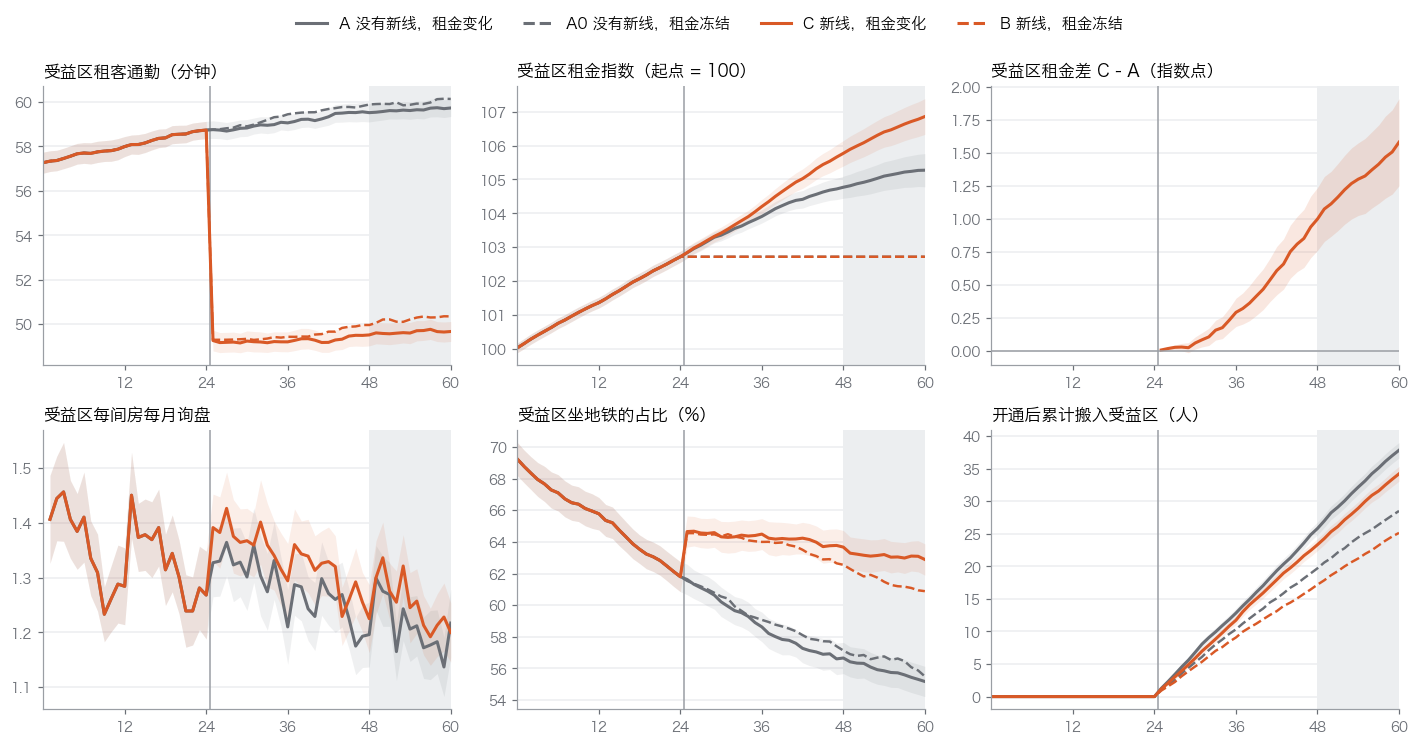

In [4]:
display(pd.DataFrame({"指标": [r["label"] for r in BASE["table"]], "基准（100 局）": [number(r, not r["key"].endswith("|C")) for r in BASE["table"]]}).set_index("指标"))
show_charts(BASE, compare=False)

## 改参数

| 参数 | 基准 | 改它是在问什么 |
|---|---|---|
| 快线省时 | 1 倍 | 新线的冲击更大或更小，结论会变吗 |
| 询盘强度 | 0.2 | 房东对需求变化更敏感，租金差会多大；这个值是假设的 |
| 低价房数量 | 1 倍 | 便宜的房子变少，低收入者还住得下吗 |
| 存款 | 1 倍 | 拿不出押金的人变多，会发生什么；存款没有真实数据 |
| 租金、工资年增速 | 都是 0 | 全市普涨时结果怎样；租金涨得比工资快时，付不起的人会走 |
| 续租涨幅比例 | 0.5 | 房东对续租者涨得更多或更少，搬家和离开会变吗；中国房东没有数据 |

虚线点是基准的 C 组，用来和本次比较。如果滑块没有显示，先从上到下运行全部。

In [ ]:
UI = show_controls()

**不用滑块也可以。** 去掉下一行开头的 `#`，直接写想改的参数：

In [6]:
# run_and_show(seeds=20, saving_scale=2, low_cost=0.4)